# BigMart Sales Prediction - EDA and model graphs
Run from `D:\AMBA` (needs `data/` folder). Each figure is displayed here and saved as a PNG in `plots/`.

In [1]:
import os, numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor as H
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
D="data"; O="plots"; os.makedirs(O,exist_ok=True); T="Item_Outlet_Sales"
tr=pd.read_csv(os.path.join(D,"train_v9rqX0R.csv")); te=pd.read_csv(os.path.join(D,"test_AbJTz2l.csv"))
plt.rcParams.update({"figure.dpi":120,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25})
C="#2a6fdb"
def save(n): plt.tight_layout(); plt.savefig(os.path.join(O,n)); plt.show()

## Target distribution

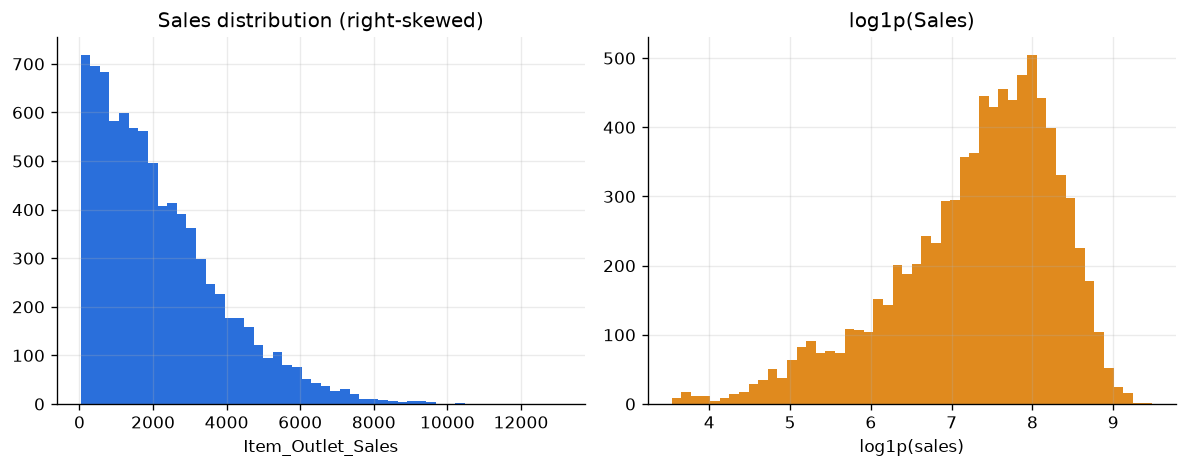

In [2]:
# 1 target distribution
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].hist(tr[T],bins=50,color=C); ax[0].set_title("Sales distribution (right-skewed)"); ax[0].set_xlabel("Item_Outlet_Sales")
ax[1].hist(np.log1p(tr[T]),bins=50,color="#e08a1e"); ax[1].set_title("log1p(Sales)"); ax[1].set_xlabel("log1p(sales)")
save("1_sales_distribution.png")

## Sales vs MRP

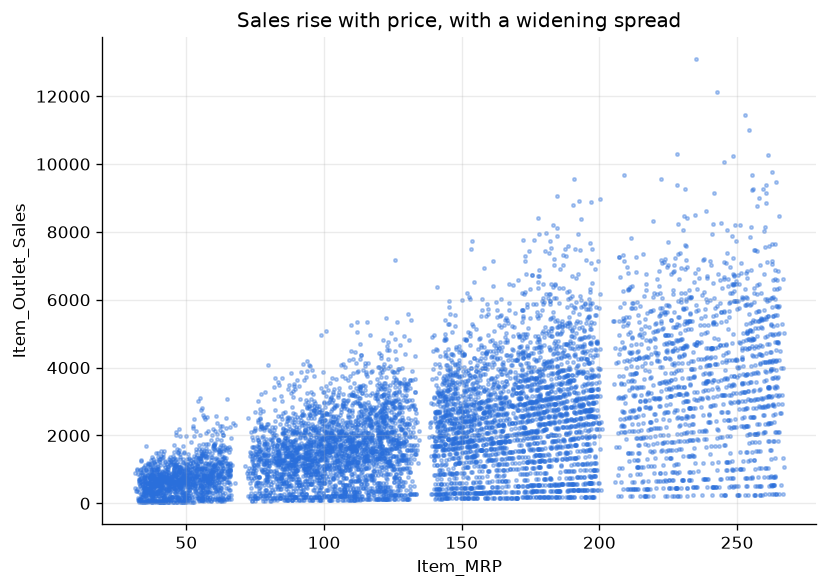

In [3]:
# 2 sales vs MRP
fig,ax=plt.subplots(figsize=(7,5)); ax.scatter(tr.Item_MRP,tr[T],s=4,alpha=.35,color=C)
ax.set_xlabel("Item_MRP"); ax.set_ylabel("Item_Outlet_Sales"); ax.set_title("Sales rise with price, with a widening spread"); save("2_sales_vs_mrp.png")

## Mean sales by outlet

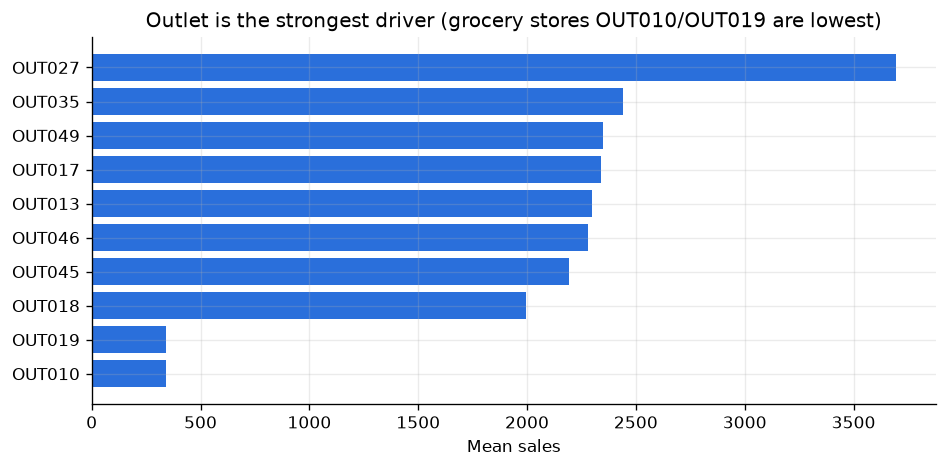

In [4]:
# 3 outlet mean sales
g=tr.groupby("Outlet_Identifier")[T].mean().sort_values()
fig,ax=plt.subplots(figsize=(8,4)); ax.barh(g.index,g.values,color=C); ax.set_xlabel("Mean sales"); ax.set_title("Outlet is the strongest driver (grocery stores OUT010/OUT019 are lowest)"); save("3_sales_by_outlet.png")

## Sales by outlet type

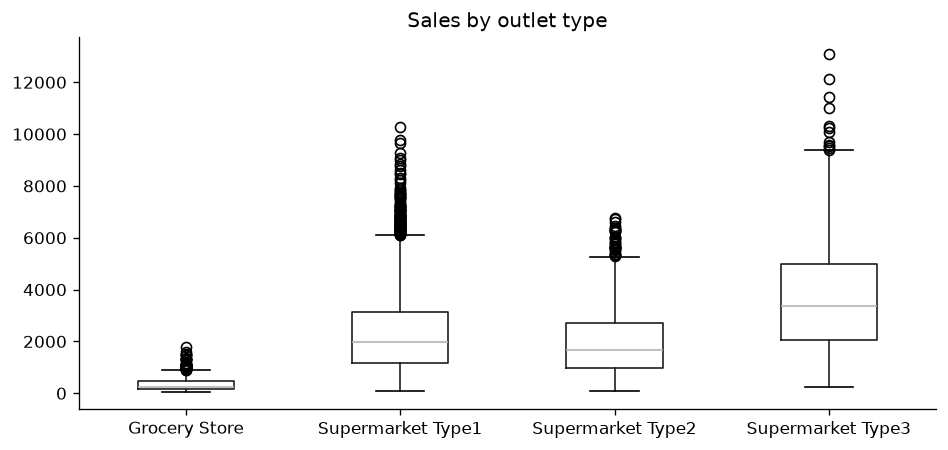

In [5]:
# 4 sales by outlet type
fig,ax=plt.subplots(figsize=(8,4)); tr.boxplot(column=T,by="Outlet_Type",ax=ax,grid=False); ax.set_title("Sales by outlet type"); fig.suptitle(""); ax.set_xlabel(""); save("4_sales_by_outlet_type.png")

## Missing values

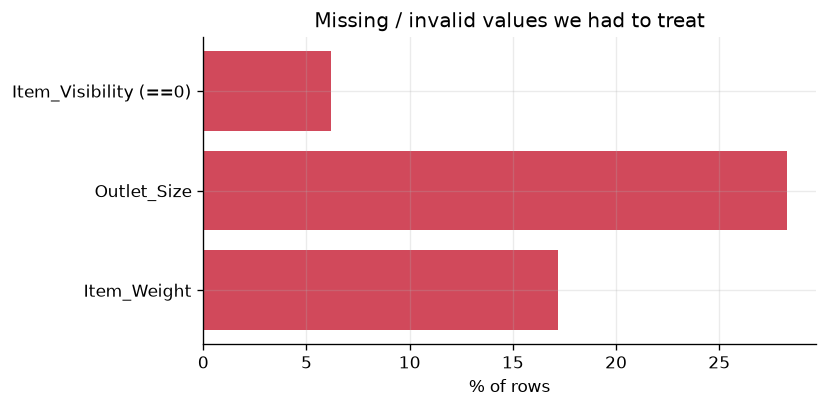

In [6]:
# 5 missing values
m=pd.concat([tr,te]).drop(columns=T).isna().mean()*100; m=m[m>0]
z=(pd.concat([tr,te]).Item_Visibility==0).mean()*100
m["Item_Visibility (==0)"]=z
fig,ax=plt.subplots(figsize=(7,3.5)); ax.barh(m.index,m.values,color="#d1495b"); ax.set_xlabel("% of rows"); ax.set_title("Missing / invalid values we had to treat"); save("5_missing_values.png")

## Model comparison (CV RMSE from experiments)

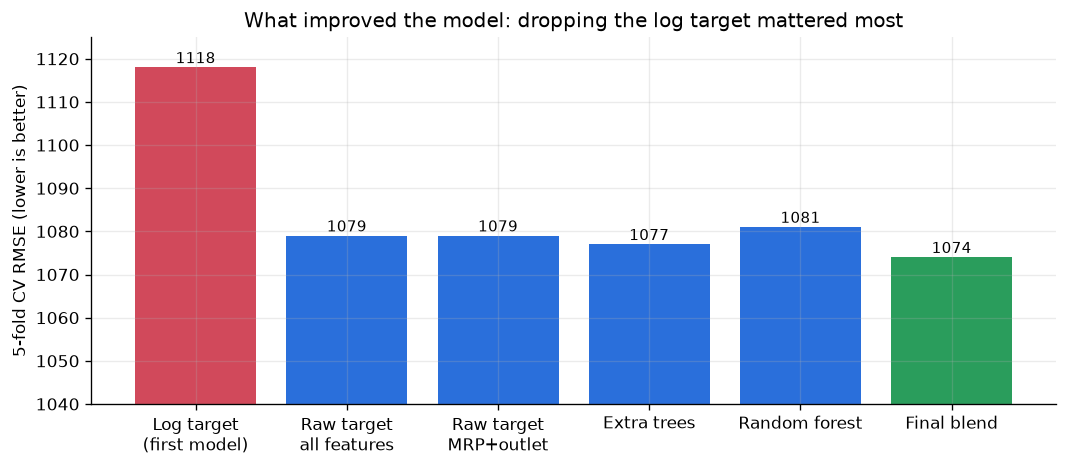

In [7]:
# 6 CV comparison (values measured during experiments)
res={"Log target\n(first model)":1118,"Raw target\nall features":1079,"Raw target\nMRP+outlet":1079,"Extra trees":1077,"Random forest":1081,"Final blend":1074}
fig,ax=plt.subplots(figsize=(9,4)); b=ax.bar(res.keys(),res.values(),color=[ "#d1495b"]+[C]*4+["#2a9d5c"])
ax.set_ylim(1040,1125); ax.set_ylabel("5-fold CV RMSE (lower is better)"); ax.set_title("What improved the model: dropping the log target mattered most")
for r,v in zip(b,res.values()): ax.text(r.get_x()+r.get_width()/2,v+1,v,ha="center",fontsize=9)
save("6_model_comparison.png")

## Out-of-fold predicted vs actual (final model)

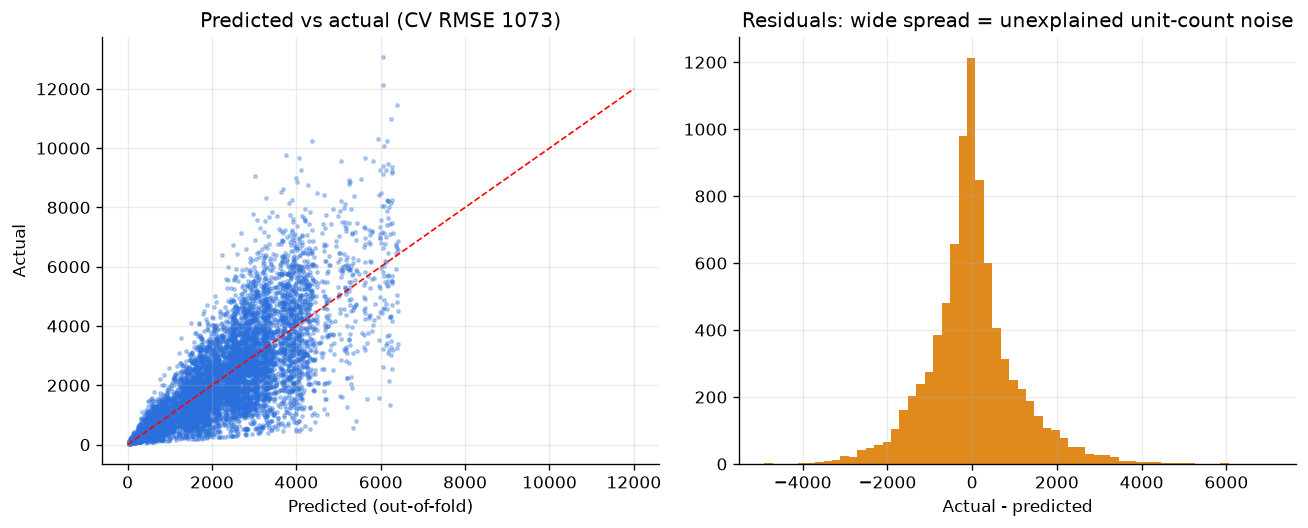

In [8]:
# 7 OOF predicted vs actual + residuals using final model
F=["Item_MRP","Outlet_Identifier"]
X=tr[F].copy(); X["Outlet_Identifier"]=X.Outlet_Identifier.astype("category").cat.codes; y=tr[T].values
def fe(m): m=np.asarray(m); return np.c_[m,m**2,(m>69)*(m-69),(m>136)*(m-136),(m>203)*(m-203)]
def fp(Xa,ya,Xb):
    gb=H(categorical_features=[False,True],random_state=0,learning_rate=.03,max_iter=250,max_depth=3,min_samples_leaf=80,l2_regularization=1.0).fit(Xa,ya).predict(Xb)
    l=np.zeros(len(Xb))
    for o in Xa.Outlet_Identifier.unique():
        a=(Xa.Outlet_Identifier==o).values; b_=(Xb.Outlet_Identifier==o).values
        if b_.any(): l[b_]=Ridge(1.0).fit(fe(Xa.Item_MRP[a]),ya[a]).predict(fe(Xb.Item_MRP[b_]))
    return np.clip((gb+l)/2,0,None)
oof=np.zeros(len(y))
for a,b_ in KFold(5,shuffle=True,random_state=1).split(X): oof[b_]=fp(X.iloc[a],y[a],X.iloc[b_])
rmse=np.sqrt(np.mean((oof-y)**2))
fig,ax=plt.subplots(1,2,figsize=(11,4.5))
ax[0].scatter(oof,y,s=4,alpha=.3,color=C); ax[0].plot([0,12000],[0,12000],"r--",lw=1); ax[0].set_xlabel("Predicted (out-of-fold)"); ax[0].set_ylabel("Actual"); ax[0].set_title(f"Predicted vs actual (CV RMSE {rmse:.0f})")
ax[1].hist(y-oof,bins=60,color="#e08a1e"); ax[1].set_title("Residuals: wide spread = unexplained unit-count noise"); ax[1].set_xlabel("Actual - predicted")
save("7_predicted_vs_actual.png")

## Per-outlet fits

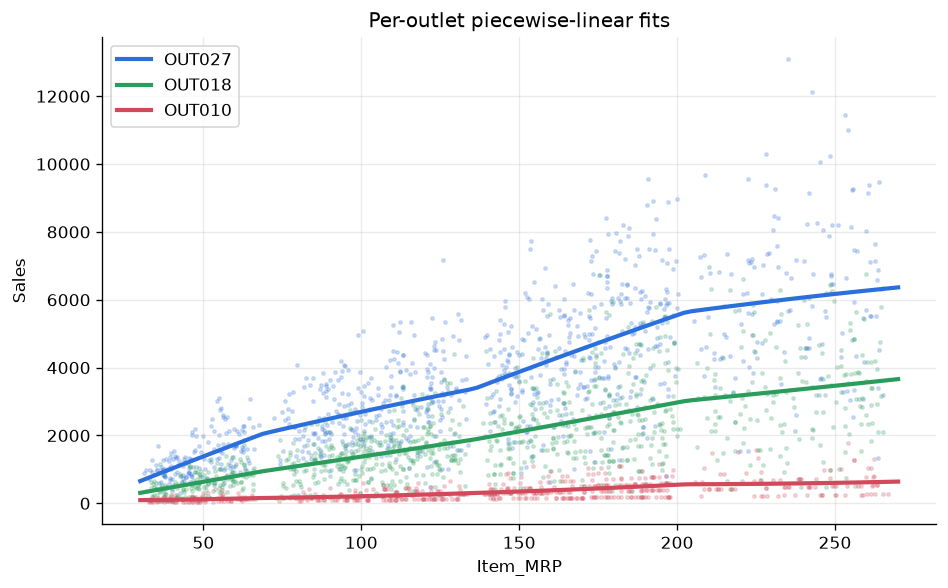

ok 1072.5743408596536


In [9]:
# 8 fitted curves for 3 outlets
fig,ax=plt.subplots(figsize=(8,5)); gr=np.linspace(30,270,100)
for o,col in zip(["OUT027","OUT018","OUT010"],[C,"#2a9d5c","#d1495b"]):
    d=tr[tr.Outlet_Identifier==o]; ax.scatter(d.Item_MRP,d[T],s=4,alpha=.2,color=col)
    ax.plot(gr,Ridge(1.0).fit(fe(d.Item_MRP),d[T]).predict(fe(gr)),color=col,lw=2.5,label=o)
ax.set_xlabel("Item_MRP"); ax.set_ylabel("Sales"); ax.set_title("Per-outlet piecewise-linear fits"); ax.legend(); save("8_per_outlet_fits.png")
print("ok",rmse)